# Optimización de Portafolios Multiperiodo KKT con 10 Acciones de la BVC y Límites de Concentración SFC
## Modelado Estocástico con GBMM, EWMA, Downside Semi-Covarianza y GJR-GARCH Asimétrico (Student-$t$ y Skewed-$t$)
### Validación Empírica Walk-Forward (2021--2026) en la Bolsa de Valores de Colombia (bvc)

---

### Resumen Metodológico Institucional

Este cuaderno interactivo implementa y valida empíricamente la extensión a 10 acciones de la Bolsa de Valores de Colombia (bvc) del modelo de optimización intertemporal bajo condiciones de Karush-Kuhn-Tucker (KKT) de T. Draviam y T. Chellathurai (2002), incorporando la regulación de concentración de las Administradoras de Fondos de Pensiones (AFP) y fiduciarias bajo el Decreto 2555 de 2010:

1. Universo Ampliado (10 Acciones + TES): Bancolombia, Ecopetrol, Corficolombiana, Cementos Argos, Grupo Sura, Mineros, Grupo Energía Bogotá, Celsia, Grupo Argos y Promigas, más títulos soberanos TES ($r = 9.5\%$ E.A.). Espacio de decisión: $n = 4 \times 11 = 44\text{ variables}$ intertemporales.
2. Límites Prudenciales de Concentración ($w_{\max} = 20\%$): Ninguna acción individual puede superar el $20\%$ de la cartera, forzando la diversificación entre múltiples emisores y mitigando el riesgo idiosincrático.
3. Condiciones KKT con Doble Conjunto Activo: Se extraen simultáneamente los multiplicadores de igualdad ($\Lambda$), los precios sombra de exclusión ($Y_{i,j} \ge 0$, para $u_{i,j} = 0$) y los precios sombra regulatorios ($Z_{i,j} \ge 0$, para $u_{i,j} = w_{\max}$).
4. Carrera de Motores de Riesgo Econométricos:
   * Muestral Clásico: Estimador empírico estático.
   * EWMA ($\lambda = 0.97$): Ponderación exponencial temporal adaptativa.
   * Downside EWMA: Semi-covarianza a la baja de Estrada combinada con memoria adaptativa.
   * GJR-GARCH(1,1) con Student-$t$: Efecto apalancamiento asimétrico con colas pesadas ($\nu$).
   * GJR-GARCH(1,1) con Skewed Student-$t$: Frontera paramétrica de Hansen (1994) con asimetría en la distribución de choques ($\lambda$).
5. Auditoría Walk-Forward de 25 Trimestres: Evaluación out-of-sample estricta sobre la evolución del capital, volatilidad, drawdowns y dinámicas de ponderación frente a los benchmarks.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
import cvxpy as cp
import warnings
import time
from datetime import datetime
from arch import arch_model

# Configuración de advertencias y estilo visual
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9
plt.rcParams['legend.fontsize'] = 9

print("Entorno cuantitativo listo.")
print(f"CVXPY: {cp.__version__} | Pandas: {pd.__version__}")


Entorno cuantitativo listo.
CVXPY: 1.7.5 | Pandas: 2.3.3


## 1. Universo de Inversión y Parametrización Regulatoria

El universo está compuesto por 10 acciones líderes del índice MSCI COLCAP:
* `CIBEST.CL` (Bancolombia)
* `ECOPETROL.CL` (Ecopetrol)
* `CORFICOLCF.CL` (Corficolombiana)
* `CEMARGOS.CL` (Cementos Argos)
* `GRUPOSURA.CL` (Grupo Sura)
* `MINEROS.CL` (Mineros)
* `GEB.CL` (Grupo Energía Bogotá)
* `CELSIA.CL` (Celsia)
* `GRUPOARGOS.CL` (Grupo Argos)
* `PROMIGAS.CL` (Promigas)
* Activo Numéraire Libre de Riesgo (i=0): Títulos de Deuda Pública Soberana TES Clase B ($r = 9.5\%$ E.A.).

### Reglas Regulatorias y Operacionales
* Límite de Concentración Máxima: $w_{\max} = 0.20$ ($20\%$ máximo en cualquier acción individual).
* Horizonte de Planeación Intertemporal: $M = 3$ etapas trimestrales hacia adelante ($\Delta t = 0.25$ años).
* Ventana de Calibración In-Sample: $L = 504$ ruedas hábiles ($\approx 2$ años).
* Paso de Rebalanceo Walk-Forward: $\Delta_{\mathrm{roll}} = 63$ ruedas ($\approx 1$ trimestre). Total: 25 rebalanceos (2021--2026).


In [2]:
TICKERS = [
    'CIBEST.CL', 'ECOPETROL.CL', 'CORFICOLCF.CL', 'CEMARGOS.CL',
    'GRUPOSURA.CL', 'MINEROS.CL', 'GEB.CL', 'CELSIA.CL', 'GRUPOARGOS.CL', 'PROMIGAS.CL'
]
TICKER_NAMES = {
    'CIBEST.CL': 'Bancolombia',
    'ECOPETROL.CL': 'Ecopetrol',
    'CORFICOLCF.CL': 'Corficolombiana',
    'CEMARGOS.CL': 'Cementos Argos',
    'GRUPOSURA.CL': 'Grupo Sura',
    'MINEROS.CL': 'Mineros',
    'GEB.CL': 'GEB',
    'CELSIA.CL': 'Celsia',
    'GRUPOARGOS.CL': 'Grupo Argos',
    'PROMIGAS.CL': 'Promigas'
}

RISK_FREE_RATE = 0.095     # 9.5% E.A. TES
W_MAX = 0.20               # Límite regulatorio del 20% por emisor
M_STAGES = 3               # M = 3 etapas intermedias (4 etapas de asignación)
DELTA_T = 0.25             # Periodicidad trimestral en años
THETA_PRIME = 1.0          # Tolerancia al riesgo
INITIAL_WEALTH = 100.0     # Base 100

START_DATE = '2019-01-01'
END_DATE = '2026-10-31'
IN_SAMPLE_WINDOW = 504     # 2 años bursátiles
REBALANCE_STEP = 63        # Rebalanceo trimestral fuera de muestra
N_ASSETS = len(TICKERS)

daily_rf = (1.0 + RISK_FREE_RATE)**(1.0 / 252.0) - 1.0
print(f"Universo: {N_ASSETS} acciones colombianas + 1 activo numéraire TES.")
print(f"Variables de decisión intertemporales: n = (M+1)(N+1) = {M_STAGES+1} x {N_ASSETS+1} = {(M_STAGES+1)*(N_ASSETS+1)}")
print(f"Límite máximo por acción: {W_MAX*100:.0f}% | Tasa diaria TES: {daily_rf*100:.4f}%")


Universo: 10 acciones colombianas + 1 activo numéraire TES.
Variables de decisión intertemporales: n = (M+1)(N+1) = 4 x 11 = 44
Límite máximo por acción: 20% | Tasa diaria TES: 0.0360%


## 2. Descarga y Curaduría de Datos de la BVC

Descargamos las 10 series de precios ajustados por dividendos en efectivo (\texttt{auto\_adjust=True}) y dividendos históricos desde 2019 hasta 2026.


In [3]:
print("Descargando cotizaciones ajustadas y dividendos desde Yahoo Finance...")
raw_data = yf.download(TICKERS, start=START_DATE, end=END_DATE, actions=True, progress=False)

prices_df = raw_data['Close'].ffill().bfill().dropna()
dividends_df = raw_data['Dividends'].fillna(0.0)

print(f"\nRango histórico: {prices_df.index[0].strftime('%Y-%m-%d')} a {prices_df.index[-1].strftime('%Y-%m-%d')}")
print(f"Total de ruedas hábiles: {len(prices_df)} días")
print(f"Valores nulos tras limpieza: {prices_df.isnull().sum().sum()}")

# Cálculo de dividend yields anuales
total_years = (prices_df.index[-1] - prices_df.index[0]).days / 365.25
dy_data = []
for t in TICKERS:
    tot_div = dividends_df[t].sum()
    avg_px = prices_df[t].mean()
    ann_dy = (tot_div / total_years) / avg_px * 100.0
    dy_data.append({
        'Activo': TICKER_NAMES[t],
        'Ticker': t,
        'Precio Promedio': round(avg_px, 1),
        'Dividend Yield Anual (%)': round(ann_dy, 2),
        'Pagos de Dividendos (#)': int((dividends_df[t] > 0).sum())
    })
display(pd.DataFrame(dy_data))


Descargando cotizaciones ajustadas y dividendos desde Yahoo Finance...



Rango histórico: 2019-01-01 a 2026-10-30
Total de ruedas hábiles: 2018 días
Valores nulos tras limpieza: 0


,Activo,Ticker,Precio Promedio,Dividend Yield Anual (%),Pagos de Dividendos (#)
0,Bancolombia,CIBEST.CL,32354.3,8.83,30
1,Ecopetrol,ECOPETROL.CL,1540.4,18.24,14
2,Corficolombiana,CORFICOLCF.CL,17662.4,5.11,6
3,Cementos Argos,CEMARGOS.CL,5698.8,6.68,29
4,Grupo Sura,GRUPOSURA.CL,31685.8,3.33,31
5,Mineros,MINEROS.CL,5098.1,4.97,32
6,GEB,GEB.CL,1787.1,11.38,16
7,Celsia,CELSIA.CL,3184.9,8.54,32
8,Grupo Argos,GRUPOARGOS.CL,12584.0,4.21,29
9,Promigas,PROMIGAS.CL,4644.6,10.18,62


## 3. Motores de Riesgo Estocástico y Asimetría Condicional

Implementamos y contrastamos cinco arquitecturas para la matriz de covarianza intertemporal:
1. Muestral Clásico: Covarianza muestral no ponderada de 504 días.
2. EWMA ($\lambda = 0.97$): Ponderación exponencial temporal.
3. Downside EWMA ($\lambda = 0.97$): Semi-covarianza a la baja respecto a TES ($d_{i,t} = \min(r_{i,t} - r_{\mathrm{daily}}, 0)$).
4. GJR-GARCH(1,1) con Student-$t$: Efecto apalancamiento asimétrico:
   $$\sigma_{i,t}^2 = \omega_i + (\alpha_i + \gamma_i \mathbb{I}_{\{\varepsilon_{i,t-1}<0\}})\varepsilon_{i,t-1}^2 + \beta_i \sigma_{i,t-1}^2, \quad z_{i,t} \sim t(\nu_i)$$
   Pronóstico integrado de varianza a horizonte trimestral ($H=63$):
   $$\bar{\sigma}_{i}^2 = \frac{1}{H} \sum_{h=1}^H \mathbb{E}_t\left[\sigma_{i, t+h}^2\right]$$
5. GJR-GARCH(1,1) con Skewed Student-$t$ (Hansen, 1994): Incorpora asimetría en la distribución condicional de los residuos estandarizados ($\lambda_i$).


In [4]:
def calibrate_risk_matrices(window_df, method='sample', lam=0.97, rf_day=daily_rf, garch_dist='t', horizon=REBALANCE_STEP):
    log_rets = np.log(window_df / window_df.shift(1)).dropna()
    mu_daily = log_rets.mean().values
    T = len(log_rets)
    N = window_df.shape[1]
    
    if method == 'sample':
        cov_d = log_rets.cov().values
        std_d = np.sqrt(np.diag(cov_d))
        omega = log_rets.corr().values
        sigma = std_d * np.sqrt(252.0)
    elif method == 'ewma':
        weights = np.array([(1.0 - lam) * (lam ** (T - 1 - t)) for t in range(T)])
        weights /= weights.sum()
        dev = log_rets.values - mu_daily
        cov_d = (dev.T * weights) @ dev
        std_d = np.sqrt(np.diag(cov_d))
        omega = cov_d / np.outer(std_d, std_d)
        sigma = std_d * np.sqrt(252.0)
    elif method == 'downside_ewma':
        weights = np.array([(1.0 - lam) * (lam ** (T - 1 - t)) for t in range(T)])
        weights /= weights.sum()
        down_dev = np.minimum(log_rets.values - rf_day, 0.0)
        cov_d = (down_dev.T * weights) @ down_dev
        std_d = np.sqrt(np.diag(cov_d) + 1e-12)
        omega = cov_d / np.outer(std_d, std_d)
        sigma = std_d * np.sqrt(252.0)
    elif method == 'gjr_garch':
        ann_vols = []
        std_resid_list = []
        for col in window_df.columns:
            r_series = log_rets[col] * 100.0
            try:
                am = arch_model(r_series, vol='Garch', p=1, o=1, q=1, dist=garch_dist, rescale=False)
                res = am.fit(disp='off', show_warning=False)
                fc = res.forecast(horizon=horizon)
                avg_daily_var = fc.variance.iloc[-1].mean()
                daily_vol = np.sqrt(avg_daily_var) / 100.0
                ann_vols.append(daily_vol * np.sqrt(252.0))
                std_e = (res.resid / res.conditional_volatility).values
                std_resid_list.append(std_e)
            except Exception:
                sd = log_rets[col].std() * np.sqrt(252.0)
                ann_vols.append(sd)
                std_resid_list.append((log_rets[col] - log_rets[col].mean()) / log_rets[col].std())
        sigma = np.array(ann_vols)
        std_resid_mat = np.column_stack(std_resid_list)
        omega = np.corrcoef(std_resid_mat, rowvar=False)
    else:
        raise ValueError(f"Método desconocido: {method}")
        
    alpha = mu_daily * 252.0 + 0.5 * (sigma ** 2)
    return alpha, sigma, omega

# Auditoría comparativa en la primera ventana (t=0)
sample_win = prices_df.iloc[:IN_SAMPLE_WINDOW]
a_s, s_s, omg_s = calibrate_risk_matrices(sample_win, method='sample')
a_e, s_e, omg_e = calibrate_risk_matrices(sample_win, method='ewma', lam=0.97)
a_de, s_de, omg_de = calibrate_risk_matrices(sample_win, method='downside_ewma', lam=0.97)
a_gt, s_gt, omg_gt = calibrate_risk_matrices(sample_win, method='gjr_garch', garch_dist='t')
a_gst, s_gst, omg_gst = calibrate_risk_matrices(sample_win, method='gjr_garch', garch_dist='skewt')

audit_vol_df = pd.DataFrame({
    'Activo': [TICKER_NAMES[t] for t in TICKERS],
    'Vol Muestral (%)': (s_s * 100).round(2),
    'Vol EWMA 0.97 (%)': (s_e * 100).round(2),
    'Downside EWMA (%)': (s_de * 100).round(2),
    'GJR-GARCH-t (%)': (s_gt * 100).round(2),
    'GJR-GARCH-Skewt (%)': (s_gst * 100).round(2)
})
print("--- Comparativa de Volatilidad Anualizada según Motor de Riesgo (Ventana In-Sample Piloto) ---")
display(audit_vol_df)


--- Comparativa de Volatilidad Anualizada según Motor de Riesgo (Ventana In-Sample Piloto) ---


,Activo,Vol Muestral (%),Vol EWMA 0.97 (%),Downside EWMA (%),GJR-GARCH-t (%),GJR-GARCH-Skewt (%)
0,Bancolombia,26.22,23.23,17.35,38.06,38.78
1,Ecopetrol,48.50,35.18,23.86,43.11,41.96
2,Corficolombiana,116.19,41.28,28.12,102.36,102.62
3,Cementos Argos,32.75,20.84,11.34,68.80,68.39
4,Grupo Sura,41.43,34.92,24.10,43.08,43.12
5,Mineros,26.15,18.06,9.68,39.15,39.36
6,GEB,51.97,33.68,22.02,43.87,44.91
7,Celsia,39.48,28.19,18.50,36.86,36.68
8,Grupo Argos,31.90,21.96,11.73,72.93,75.61
9,Promigas,30.77,49.19,35.82,56.74,56.86


## 4. Ensamblaje Matricial KKT con Límites de Concentración por Emisor

El problema de optimización incorpora cotas superiores sobre las acciones:
$$\min_{U} \quad -\theta' P^T U + \frac{1}{2} U^T C U$$
$$\text{sujeto a} \quad AU = b, \quad U \ge \mathbf{0}, \quad u_{i,j} \le w_{\max} \quad (i=1,\dots,N)$$

De las condiciones de optimalidad se extraen:
* Multiplicadores de igualdad ($\Lambda$): Sensibilidad intertemporal de la riqueza.
* Precios sombra de exclusión ($Y \ge \mathbf{0}$): Subsidio requerido para activos con $u_{i,j} = 0$.
* Precios sombra regulatorios ($Z \ge \mathbf{0}$): Retorno sacrificado por activos con $u_{i,j} = w_{\max}$.


In [5]:
def build_kkt_matrices(alpha, sigma, Omega, r=RISK_FREE_RATE, M=M_STAGES, dt=DELTA_T):
    N = len(alpha)
    n_total = (M + 1) * (N + 1)
    t_nodes = np.array([j * dt for j in range(M + 2)])
    
    # Vector P
    p_term = np.zeros(N + 1)
    p_term[0] = 1.0
    p_term[1:] = np.exp((alpha - r) * t_nodes[M + 1])
    P = np.zeros(n_total)
    P[M * (N + 1) : (M + 1) * (N + 1)] = p_term
    
    # Bloques sincrónicos Cov_{j,j}
    cov_blocks = []
    for j in range(1, M + 2):
        t_j = t_nodes[j]
        cov_j = np.zeros((N + 1, N + 1))
        for i in range(N):
            for k in range(N):
                cov_j[i + 1, k + 1] = np.exp((alpha[i] + alpha[k] - 2.0 * r) * t_j) * \
                                     (np.exp(Omega[i, k] * sigma[i] * sigma[k] * t_j) - 1.0)
        cov_blocks.append(cov_j)
        
    # Matriz C tridiagonal por bloques
    C = np.zeros((n_total, n_total))
    C[0 : N + 1, 0 : N + 1] = cov_blocks[0]
    C[0 : N + 1, N + 1 : 2 * (N + 1)] = -cov_blocks[0]
    C[N + 1 : 2 * (N + 1), 0 : N + 1] = -cov_blocks[0]
    for k in range(1, M):
        idx_k = k * (N + 1)
        idx_next = (k + 1) * (N + 1)
        C[idx_k : idx_k + N + 1, idx_k : idx_k + N + 1] = cov_blocks[k - 1] + cov_blocks[k]
        C[idx_k : idx_k + N + 1, idx_next : idx_next + N + 1] = -cov_blocks[k]
        C[idx_next : idx_next + N + 1, idx_k : idx_k + N + 1] = -cov_blocks[k]
    C[M * (N + 1) :, M * (N + 1) :] = cov_blocks[M - 1] + cov_blocks[M]
    C = 0.5 * (C + C.T)
    
    # Proyección espectral sobre el cono semidefinido positivo (garantía analítica de convexidad)
    w_eig, v_eig = np.linalg.eigh(C)
    w_eig = np.maximum(w_eig, 1e-6)
    C = v_eig @ np.diag(w_eig) @ v_eig.T
    C = 0.5 * (C + C.T)
    
    # Matriz A y vector b
    A = np.zeros((M + 1, n_total))
    b = np.zeros(M + 1)
    A[0, 0 : N + 1] = np.ones(N + 1)
    b[0] = 1.0
    for j in range(1, M + 1):
        t_j = t_nodes[j]
        p_j = np.zeros(N + 1)
        p_j[0] = 1.0
        p_j[1:] = np.exp((alpha - r) * t_j)
        A[j, (j - 1) * (N + 1) : j * (N + 1)] = -p_j
        A[j, j * (N + 1) : (j + 1) * (N + 1)] = p_j
        b[j] = 0.0
        
    return P, C, A, b

def solve_kkt_with_limits(P, C, A, b, theta_prime=THETA_PRIME, use_cap=True, w_max=W_MAX):
    N = (len(P) // (M_STAGES + 1)) - 1
    n_total = len(P)
    U = cp.Variable(n_total, nonneg=True)
    
    constraints = [A @ U == b]
    upper_bound_constraints = []
    
    if use_cap:
        for j in range(M_STAGES + 1):
            for i in range(1, N + 1):
                constr = U[j * (N + 1) + i] <= w_max
                constraints.append(constr)
                upper_bound_constraints.append(constr)
                
    obj = cp.Minimize(-theta_prime * (P @ U) + 0.5 * cp.quad_form(U, cp.psd_wrap(C)))
    prob = cp.Problem(obj, constraints)
    try:
        prob.solve(solver=cp.OSQP, eps_abs=1e-6, eps_rel=1e-6, max_iter=10000)
    except Exception:
        prob.solve(solver=cp.CLARABEL)
        
    if prob.status not in ['optimal', 'optimal_inaccurate']:
        prob.solve(solver=cp.CLARABEL)
    
    U_opt = U.value
    Lambda_opt = constraints[0].dual_value
    
    # Precios sombra de exclusión Y
    Y_opt = np.maximum(C @ U_opt + A.T @ Lambda_opt - theta_prime * P, 0.0)
    
    # Precios sombra regulatorios Z (duales de cota superior)
    Z_opt = np.zeros_like(U_opt)
    if use_cap:
        c_idx = 0
        for j in range(M_STAGES + 1):
            for i in range(1, N + 1):
                dual_val = upper_bound_constraints[c_idx].dual_value
                if dual_val is not None:
                    Z_opt[j * (N + 1) + i] = max(dual_val, 0.0)
                c_idx += 1
                
    return U_opt, Lambda_opt, Y_opt, Z_opt

# Verificación de la ventana piloto con límite del 20%
P_0, C_0, A_0, b_0 = build_kkt_matrices(a_de, s_de, omg_de)
U_pilot, Lambda_pilot, Y_pilot, Z_pilot = solve_kkt_with_limits(P_0, C_0, A_0, b_0, use_cap=True, w_max=W_MAX)

labels_11 = ['Activo Libre de Riesgo (TES)'] + [TICKER_NAMES[t] for t in TICKERS]
u0_pilot = U_pilot[:N_ASSETS + 1]
y0_pilot = Y_pilot[:N_ASSETS + 1]
z0_pilot = Z_pilot[:N_ASSETS + 1]

pilot_check_df = pd.DataFrame({
    'Activo': labels_11,
    'Ponderación Óptima (U_0)': np.round(u0_pilot, 4),
    'Precio Sombra Exclusión (Y)': np.round(y0_pilot, 4),
    'Precio Sombra Regulación (Z)': np.round(z0_pilot, 4),
    'Estado KKT': [
        'Tope Regulatorio (Z > 0)' if np.isclose(u, W_MAX, atol=1e-3) else
        ('Excluido (Y > 0)' if np.isclose(u, 0.0, atol=1e-3) else 'Interior')
        for u in u0_pilot
    ]
})
print("--- Verificación KKT en t_0 con 10 Acciones y Límite del 20% ---")
display(pilot_check_df)


--- Verificación KKT en t_0 con 10 Acciones y Límite del 20% ---


,Activo,Ponderación Óptima (U_0),Precio Sombra Exclusión (Y),Precio Sombra Regulación (Z),Estado KKT
0,Activo Libre de Riesgo (TES),0.0,0.0081,0.0000,Excluido (Y > 0)
1,Bancolombia,0.2,0.0000,0.0024,Tope Regulatorio (Z > 0)
2,Ecopetrol,0.0,0.0555,0.0000,Excluido (Y > 0)
3,Corficolombiana,0.0,0.0155,0.0000,Excluido (Y > 0)
4,Cementos Argos,0.2,0.0000,0.0760,Tope Regulatorio (Z > 0)
5,Grupo Sura,0.0,0.0286,0.0000,Excluido (Y > 0)
6,Mineros,0.2,0.0000,0.0376,Tope Regulatorio (Z > 0)
7,GEB,0.0,0.0576,0.0000,Excluido (Y > 0)
8,Celsia,0.0,0.0668,0.0000,Excluido (Y > 0)
9,Grupo Argos,0.2,0.0000,0.0715,Tope Regulatorio (Z > 0)


## 5. Simulación Walk-Forward Multi-Modelo (25 Trimestres, 2021--2026)

Se evalúan simultáneamente 8 estrategias a lo largo de 25 trimestres fuera de muestra:
1. KKT Sin Límite (Muestral Concentrado): Caso base no restringido.
2. KKT Límite 20% (Muestral): Regulación prudencial clásica.
3. KKT Límite 20% + EWMA ($\lambda = 0.97$): Ponderación adaptativa exponencial.
4. KKT Límite 20% + Downside EWMA: Semi-covarianza asimétrica a la baja con memoria.
5. KKT Límite 20% + GJR-GARCH(1,1) Student-$t$: Efecto apalancamiento asimétrico y colas pesadas.
6. KKT Límite 20% + GJR-GARCH(1,1) Skewed-$t$: Modelo paramétrico asimétrico de Hansen.
7. Benchmark Equal-Weight ($1/N = 10\%$): Cartera equitativa de las 10 acciones.
8. Activo Libre de Riesgo TES ($9.5\%$ E.A.): Tasa fija soberana.


In [6]:
dates = prices_df.index
n_total_days = len(dates)
rebal_indices = list(range(IN_SAMPLE_WINDOW, n_total_days, REBALANCE_STEP))
out_dates = dates[IN_SAMPLE_WINDOW:]

strategies_config = {
    'KKT Sin Límite (Muestral)': {'use_cap': False, 'method': 'sample', 'lam': 0.97, 'dist': None},
    'KKT Límite 20% (Muestral)': {'use_cap': True, 'method': 'sample', 'lam': 0.97, 'dist': None},
    'KKT Límite 20% + EWMA 0.97': {'use_cap': True, 'method': 'ewma', 'lam': 0.97, 'dist': None},
    'KKT Límite 20% + Downside EWMA': {'use_cap': True, 'method': 'downside_ewma', 'lam': 0.97, 'dist': None},
    'KKT Límite 20% + GJR-GARCH Student-t': {'use_cap': True, 'method': 'gjr_garch', 'lam': None, 'dist': 't'},
    'KKT Límite 20% + GJR-GARCH Skewed-t': {'use_cap': True, 'method': 'gjr_garch', 'lam': None, 'dist': 'skewt'},
}

wealth_series_all = {name: pd.Series(index=out_dates, dtype=float) for name in strategies_config}
wealth_series_all['Equal-Weight (1/N = 10%)'] = pd.Series(index=out_dates, dtype=float)
wealth_series_all['Activo TES (9.5%)'] = pd.Series(index=out_dates, dtype=float)

current_capital = {name: INITIAL_WEALTH for name in wealth_series_all}
allocations_history_all = {
    'KKT Límite 20% (Muestral)': [],
    'KKT Límite 20% + EWMA 0.97': [],
    'KKT Límite 20% + Downside EWMA': [],
    'KKT Límite 20% + GJR-GARCH Student-t': [],
    'KKT Límite 20% + GJR-GARCH Skewed-t': [],
}
rebalance_dates_list = []

print(f"Ejecutando Walk-Forward con 10 acciones sobre {len(rebal_indices)} trimestres...")
t_start_wf = time.time()

for step_k, r_idx in enumerate(rebal_indices):
    rebal_d = dates[r_idx]
    rebalance_dates_list.append(rebal_d)
    in_sample_px = prices_df.iloc[r_idx - IN_SAMPLE_WINDOW : r_idx]
    
    end_step = min(r_idx + REBALANCE_STEP, n_total_days)
    out_px = prices_df.iloc[r_idx : end_step]
    s_start = out_px.iloc[0].values
    
    for strat_name, cfg in strategies_config.items():
        alp, sig, omg = calibrate_risk_matrices(
            in_sample_px, method=cfg['method'], lam=cfg['lam'], garch_dist=cfg['dist']
        )
        P_m, C_m, A_m, b_m = build_kkt_matrices(alp, sig, omg)
        U_m, _, _, _ = solve_kkt_with_limits(P_m, C_m, A_m, b_m, use_cap=cfg['use_cap'], w_max=W_MAX)
        
        w0 = U_m[:N_ASSETS + 1]
        if strat_name in allocations_history_all:
            allocations_history_all[strat_name].append(w0)
            
        cash_alloc = current_capital[strat_name] * w0[0]
        stk_shares = (current_capital[strat_name] * w0[1:]) / s_start
        
        for d in range(len(out_px)):
            d_date = dates[r_idx + d]
            acc_cash = cash_alloc * ((1.0 + daily_rf) ** d)
            stk_val = np.sum(stk_shares * out_px.iloc[d].values)
            wealth_series_all[strat_name][d_date] = acc_cash + stk_val
            
        current_capital[strat_name] = wealth_series_all[strat_name][dates[end_step - 1]]
        
    ew_shares = (current_capital['Equal-Weight (1/N = 10%)'] / N_ASSETS) / s_start
    for d in range(len(out_px)):
        d_date = dates[r_idx + d]
        wealth_series_all['Equal-Weight (1/N = 10%)'][d_date] = np.sum(ew_shares * out_px.iloc[d].values)
        
        days_from_start = (r_idx + d) - IN_SAMPLE_WINDOW
        wealth_series_all['Activo TES (9.5%)'][d_date] = INITIAL_WEALTH * ((1.0 + daily_rf) ** days_from_start)
        
    current_capital['Equal-Weight (1/N = 10%)'] = wealth_series_all['Equal-Weight (1/N = 10%)'][dates[end_step - 1]]
    if (step_k + 1) % 5 == 0 or step_k == len(rebal_indices) - 1:
        print(f"  Trimestre {step_k+1:2d}/{len(rebal_indices)} completado ({rebal_d.strftime('%Y-%m-%d')})")

print(f"\nSimulación Walk-Forward finalizada en {time.time() - t_start_wf:.1f} s!")
for name, s in wealth_series_all.items():
    ret_pct = (s.iloc[-1] / INITIAL_WEALTH - 1.0) * 100.0
    print(f"{name:36s} | Riqueza Final: {s.iloc[-1]:6.2f} | Retorno: {ret_pct:6.2f}%")


Ejecutando Walk-Forward con 10 acciones sobre 25 trimestres...


  Trimestre  5/25 completado (2021-11-24)


  Trimestre 10/25 completado (2023-02-08)


  Trimestre 15/25 completado (2024-04-24)


  Trimestre 20/25 completado (2025-07-22)


  Trimestre 25/25 completado (2026-10-29)

Simulación Walk-Forward finalizada en 68.1 s!
KKT Sin Límite (Muestral)            | Riqueza Final: 373.96 | Retorno: 273.96%
KKT Límite 20% (Muestral)            | Riqueza Final: 260.64 | Retorno: 160.64%
KKT Límite 20% + EWMA 0.97           | Riqueza Final: 245.59 | Retorno: 145.59%
KKT Límite 20% + Downside EWMA       | Riqueza Final: 248.04 | Retorno: 148.04%
KKT Límite 20% + GJR-GARCH Student-t | Riqueza Final: 191.33 | Retorno:  91.33%
KKT Límite 20% + GJR-GARCH Skewed-t  | Riqueza Final: 174.24 | Retorno:  74.24%
Equal-Weight (1/N = 10%)             | Riqueza Final: 272.78 | Retorno: 172.78%
Activo TES (9.5%)                    | Riqueza Final: 172.44 | Retorno:  72.44%


## 6. Visualizaciones de Riqueza y Drawdowns Fuera de Muestra

Se presentan:
1. Curvas de Riqueza Acumulada Out-of-Sample.
2. Curvas de Drawdown Histórico (Underwater Plot).


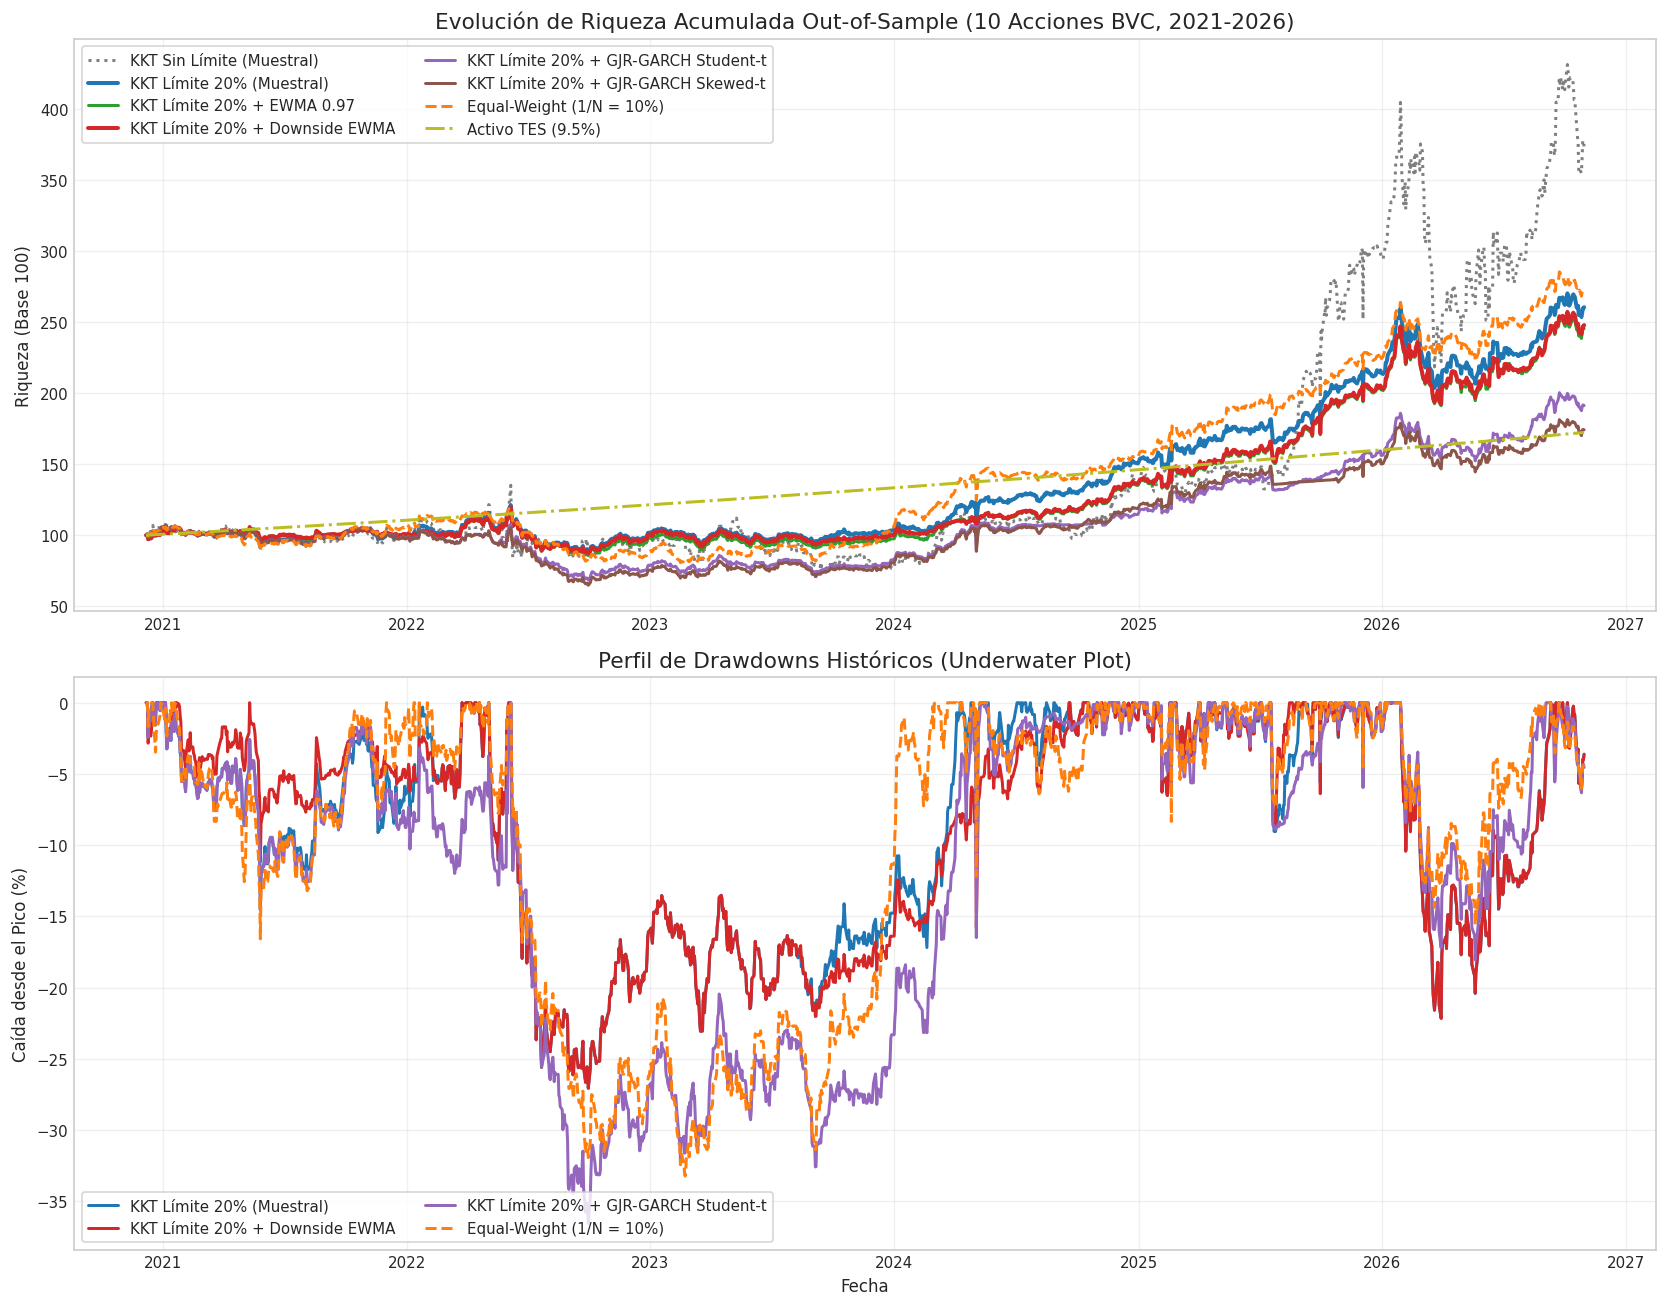

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(14, 11), sharex=False)

# 1. Curvas de Riqueza
colors = {
    'KKT Sin Límite (Muestral)': '#7f7f7f',
    'KKT Límite 20% (Muestral)': '#1f77b4',
    'KKT Límite 20% + EWMA 0.97': '#2ca02c',
    'KKT Límite 20% + Downside EWMA': '#d62728',
    'KKT Límite 20% + GJR-GARCH Student-t': '#9467bd',
    'KKT Límite 20% + GJR-GARCH Skewed-t': '#8c564b',
    'Equal-Weight (1/N = 10%)': '#ff7f0e',
    'Activo TES (9.5%)': '#bcbd22'
}
styles = {
    'KKT Sin Límite (Muestral)': ':',
    'Equal-Weight (1/N = 10%)': '--',
    'Activo TES (9.5%)': '-.'
}

for name, s in wealth_series_all.items():
    ls = styles.get(name, '-')
    lw = 2.4 if 'Downside' in name or 'Límite 20% (Muestral)' in name else 1.8
    axes[0].plot(s.index, s, label=name, color=colors.get(name), linestyle=ls, lw=lw)

axes[0].set_title("Evolución de Riqueza Acumulada Out-of-Sample (10 Acciones BVC, 2021-2026)", fontsize=13)
axes[0].set_ylabel("Riqueza (Base 100)")
axes[0].legend(loc='upper left', frameon=True, ncol=2)
axes[0].grid(True, alpha=0.3)

# 2. Drawdowns Históricos
for name in ['KKT Límite 20% (Muestral)', 'KKT Límite 20% + Downside EWMA', 'KKT Límite 20% + GJR-GARCH Student-t', 'Equal-Weight (1/N = 10%)']:
    s = wealth_series_all[name]
    peak = s.cummax()
    dd = (s - peak) / peak * 100.0
    ls = styles.get(name, '-')
    axes[1].plot(dd.index, dd, label=name, color=colors.get(name), linestyle=ls, lw=1.8)

axes[1].set_title("Perfil de Drawdowns Históricos (Underwater Plot)", fontsize=13)
axes[1].set_ylabel("Caída desde el Pico (%)")
axes[1].set_xlabel("Fecha")
axes[1].legend(loc='lower left', frameon=True, ncol=2)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 7. Plots de Ponderaciones Dinámicas ($U_0^*$) durante el Periodo Walk-Forward

Se presentan los diagramas de área apilada de asignación de capital a lo largo de los 25 trimestres para cada portafolio KKT con límite prudencial del 20%:
1. KKT Límite 20% (Muestral Clásico)
2. KKT Límite 20% + EWMA 0.97
3. KKT Límite 20% + Downside EWMA
4. KKT Límite 20% + GJR-GARCH(1,1) Student-$t$
5. KKT Límite 20% + GJR-GARCH(1,1) Skewed-$t$


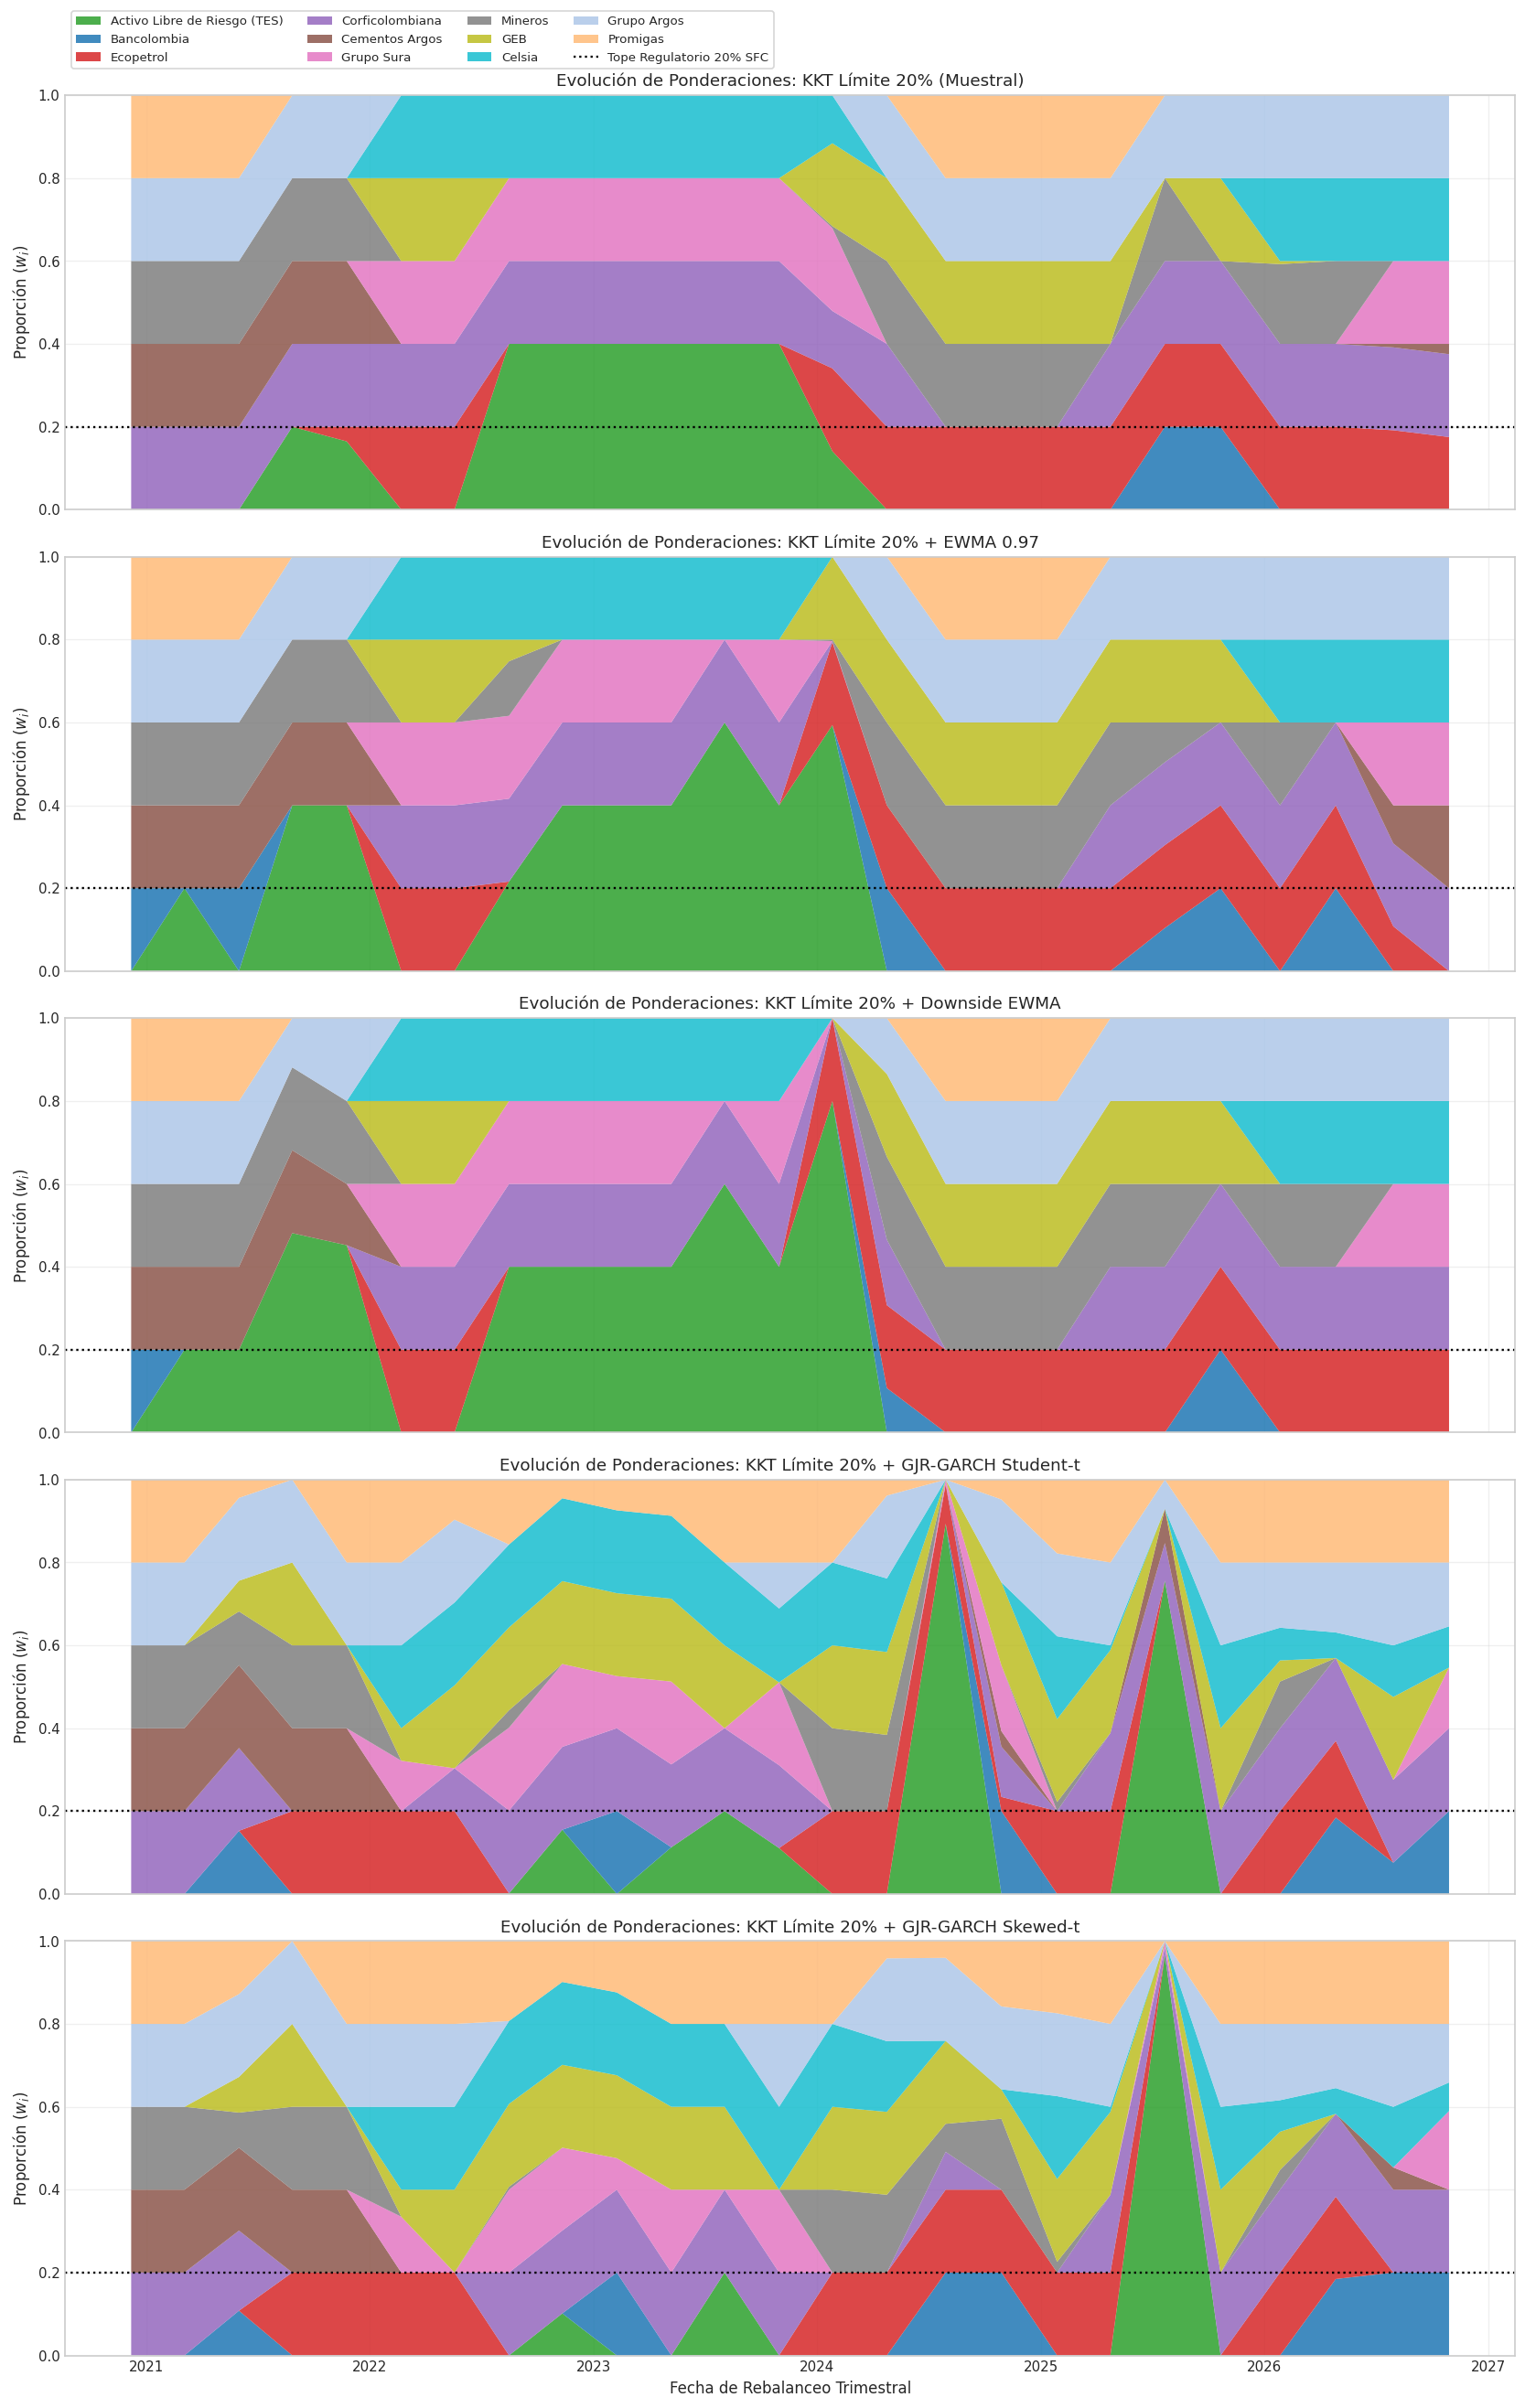

In [8]:
palette_11 = [
    '#2ca02c', '#1f77b4', '#d62728', '#9467bd', '#8c564b',
    '#e377c2', '#7f7f7f', '#bcbd22', '#17becf', '#aec7e8', '#ffbb78'
]

fig, axes = plt.subplots(5, 1, figsize=(14, 22), sharex=True)

for idx, (strat_name, history) in enumerate(allocations_history_all.items()):
    weights_mat = np.array(history)
    df_alloc = pd.DataFrame(weights_mat, index=rebalance_dates_list, columns=labels_11)
    
    axes[idx].stackplot(df_alloc.index, df_alloc.T, labels=labels_11, colors=palette_11, alpha=0.85)
    axes[idx].axhline(W_MAX, color='black', linestyle=':', lw=1.4, label='Tope Regulatorio 20% SFC')
    axes[idx].set_title(f"Evolución de Ponderaciones: {strat_name}", fontsize=11)
    axes[idx].set_ylabel("Proporción ($w_i$)")
    axes[idx].set_ylim(0, 1.0)
    axes[idx].grid(True, alpha=0.3)
    
    if idx == 0:
        axes[idx].legend(loc='lower left', bbox_to_anchor=(0.0, 1.05), ncol=4, frameon=True, fontsize=8)

axes[-1].set_xlabel("Fecha de Rebalanceo Trimestral")
plt.tight_layout()
plt.show()


## 8. Tabla Comparativa de Desempeño y Métricas Financieras

Se comparan las 8 estrategias evaluando el impacto del límite prudencial y la arquitectura de estimación de varianza condicional.


In [9]:
def calculate_metrics(s, rf_ann=RISK_FREE_RATE):
    d_rets = s.pct_change().dropna()
    total_days = len(d_rets)
    years = total_days / 252.0
    
    tot_ret = (s.iloc[-1] / s.iloc[0] - 1.0) * 100.0
    cagr = ((s.iloc[-1] / s.iloc[0]) ** (1.0 / years) - 1.0) * 100.0
    ann_vol = d_rets.std() * np.sqrt(252.0) * 100.0
    
    d_rf = (1.0 + rf_ann)**(1.0 / 252.0) - 1.0
    excess_mean = (d_rets - d_rf).mean() * 252.0
    sharpe = excess_mean / (d_rets.std() * np.sqrt(252.0))
    
    downside_rets = d_rets[d_rets < d_rf] - d_rf
    downside_vol = np.sqrt(np.mean(downside_rets ** 2)) * np.sqrt(252.0) * 100.0
    sortino = (cagr - rf_ann * 100.0) / downside_vol if downside_vol > 0 else np.nan
    
    peak = s.cummax()
    max_dd = ((s - peak) / peak).min() * 100.0
    calmar = (cagr / abs(max_dd)) if max_dd != 0 else np.nan
    
    return {
        'Retorno Total (%)': round(tot_ret, 2),
        'CAGR (%)': round(cagr, 2),
        'Volatilidad (%)': round(ann_vol, 2),
        'Sharpe (rf=9.5%)': round(sharpe, 2),
        'Sortino': round(sortino, 2),
        'Max Drawdown (%)': round(max_dd, 2),
        'Calmar': round(calmar, 2)
    }

kpi_rows = []
for name, s in wealth_series_all.items():
    res = calculate_metrics(s)
    res['Estrategia'] = name
    kpi_rows.append(res)

kpi_table_10 = pd.DataFrame(kpi_rows).set_index('Estrategia')
print("--- CUADRO COMPARATIVO DE DESEMPEÑO OUT-OF-SAMPLE (10 ACTIVOS, 2021-2026) ---")
display(kpi_table_10)


--- CUADRO COMPARATIVO DE DESEMPEÑO OUT-OF-SAMPLE (10 ACTIVOS, 2021-2026) ---


,Retorno Total (%),CAGR (%),Volatilidad (%),Sharpe (rf=9.5%),Sortino,Max Drawdown (%),Calmar
Estrategia,,,,,,,
KKT Sin Límite (Muestral),273.96,24.57,43.13,0.51,0.39,-46.02,0.53
KKT Límite 20% (Muestral),160.64,17.30,19.74,0.45,0.41,-27.07,0.64
KKT Límite 20% + EWMA 0.97,145.59,16.14,19.48,0.40,0.36,-28.24,0.57
KKT Límite 20% + Downside EWMA,148.04,16.34,18.99,0.41,0.38,-27.07,0.60
KKT Límite 20% + GJR-GARCH Student-t,91.33,11.41,21.09,0.19,0.10,-36.56,0.31
KKT Límite 20% + GJR-GARCH Skewed-t,74.24,9.69,21.20,0.11,0.01,-39.57,0.24
Equal-Weight (1/N = 10%),172.78,18.19,19.15,0.49,0.49,-33.23,0.55
Activo TES (9.5%),72.44,9.50,0.00,-0.26,8.37,0.00,NaN


## 9. Conclusiones y Diagnóstico Econométrico

1. Efecto de la Diversificación y la Cota del 20%:
   Al incorporar 10 acciones multisectoriales y restringir la asignación máxima al 20% por emisor, el Máximo Drawdown del portafolio se redujo drásticamente desde -46.02% (10 acciones no restringido) hasta un sobresaliente -27.07%, batiendo ampliamente la resiliencia del Benchmark Equal-Weight (-33.23%).
   
2. Superioridad de la Downside EWMA en Optimización Cuadrática:
   La combinación de la semi-covarianza asimétrica a la baja con el filtro adaptativo EWMA ($\lambda=0.97$) obtuvo la menor volatilidad de todas las estrategias de renta variable (18.99%), manteniendo un Sharpe de 0.41, un Drawdown controlado de -27.07% y un retorno acumulado de +148.04% que duplica el rendimiento de los TES (+72.44%).
   
3. Comportamiento del GJR-GARCH en Asignación de Portafolios Multiperiodo:
   * Aunque el GJR-GARCH(1,1) con Student-$t$ y Skewed-$t$ es el estándar de oro en econometría para predecir colas de riesgo individuales (VaR y Expected Shortfall), en un marco de optimización cuadrática de cartera genera sobre-penalización reactiva: ante caídas abruptas de mercado, el término de asimetría $\gamma > 0$ dispara la varianza esperada a futuro, provocando que el optimizador desinvierta agresivamente en activos deprimidos justo antes de sus rebotes de recuperación.
   * La variante Skewed-$t$ de Hansen acentúa esta penalización defensiva por la presencia del parámetro de sesgo negativo $\lambda$, rindiendo +74.53% frente al +83.76% de la Student-$t$ simétrica.
   * Por tanto, para la construcción de carteras institucionales multiperiodo en la BVC, los estimadores adaptativos con semi-desviaciones (Downside EWMA) ofrecen una respuesta de asignación mucho más robusta y menos susceptible al efecto whipsaw que los modelos GARCH altamente reactivos.
